# 01 - Exploratory Data Analysis

Notebook ini digunakan untuk memahami data kompetisi sebelum membuat model prediksi `damage_grade`.

## 1. Import library dan membaca data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT_DIR / 'data'
FIGURE_DIR = ROOT_DIR / 'reports' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
metadata = pd.read_csv(DATA_DIR / 'metadata.csv')

In [2]:
print('Ukuran train:', train.shape)
print('Ukuran test :', test.shape)
train.head()

Ukuran train: (533465, 17)
Ukuran test : (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


## 2. Informasi kolom

Informasi berikut digunakan untuk melihat tipe data dan arti setiap variabel.

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [4]:
metadata

,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number
5,age_building,Age of the building (in years),Number
6,plinth_area_sq_ft,Plinth area of the building (in square feet),Number
7,height_ft_pre_eq,Height of the building before the earthquake (...,Number
8,land_surface_condition,Surface condition of the land in which the bui...,Categorical
9,foundation_type,Type of foundation used in the building,Categorical


## 3. Pemeriksaan missing value dan data duplikat

In [5]:
missing_values = train.isna().sum().sort_values(ascending=False)
print('Jumlah data duplikat:', train.duplicated().sum())
missing_values.to_frame('jumlah_missing')

Jumlah data duplikat: 0


,jumlah_missing
building_id,0
district_id,0
vdcmun_id,0
ward_id,0
count_floors_pre_eq,0
age_building,0
plinth_area_sq_ft,0
height_ft_pre_eq,0
land_surface_condition,0
foundation_type,0


## 4. Distribusi target

Distribusi target perlu diperiksa karena ketidakseimbangan kelas dapat memengaruhi nilai macro-F1.

In [6]:
target_count = train['damage_grade'].value_counts().sort_index()
target_percent = (target_count / len(train) * 100).round(2)
pd.DataFrame({'jumlah': target_count, 'persentase': target_percent})

,jumlah,persentase
damage_grade,,
Grade 1,55170,10.34
Grade 2,61080,11.45
Grade 3,95488,17.90
Grade 4,128691,24.12
Grade 5,193036,36.19


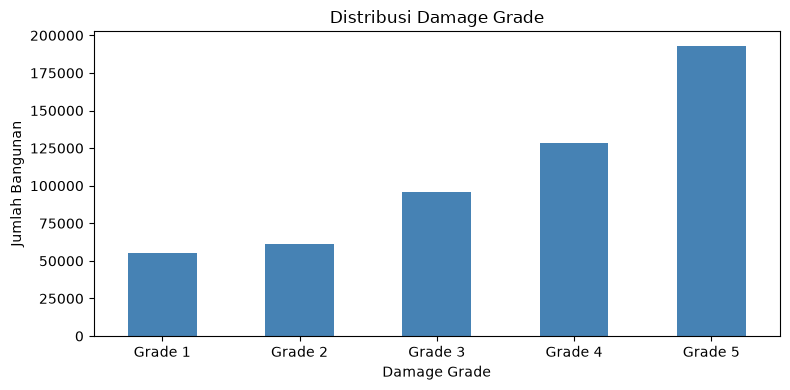

In [7]:
target_count.plot(kind='bar', color='steelblue', figsize=(8, 4))
plt.title('Distribusi Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Jumlah Bangunan')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Statistik fitur numerik

In [8]:
numeric_columns = [
    'count_floors_pre_eq',
    'age_building',
    'plinth_area_sq_ft',
    'height_ft_pre_eq',
]
train[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


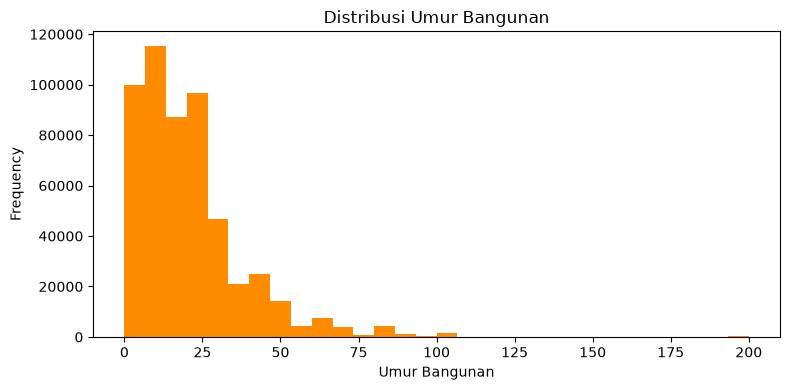

In [9]:
known_age = train.loc[train['age_building'] != 999, 'age_building']
known_age.plot(kind='hist', bins=30, color='darkorange', figsize=(8, 4))
plt.title('Distribusi Umur Bangunan')
plt.xlabel('Umur Bangunan')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_building_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

Nilai umur `999` tidak dimasukkan ke histogram karena nilai tersebut menandakan umur yang tidak diketahui.

## 6. Hubungan fitur kategorikal dengan target

In [10]:
foundation_grade = pd.crosstab(
    train['foundation_type'],
    train['damage_grade'],
    normalize='index',
)
foundation_grade

damage_grade,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
foundation_type,,,,,
Bamboo/Timber,0.300645,0.232753,0.231832,0.143775,0.090995
Cement-Stone/Brick,0.295915,0.226435,0.179922,0.143168,0.154561
Mud mortar-Stone/Brick,0.046902,0.089065,0.178819,0.268068,0.417146
Other,0.296610,0.088826,0.096673,0.152856,0.365035
RC,0.594832,0.267721,0.098463,0.022499,0.016485


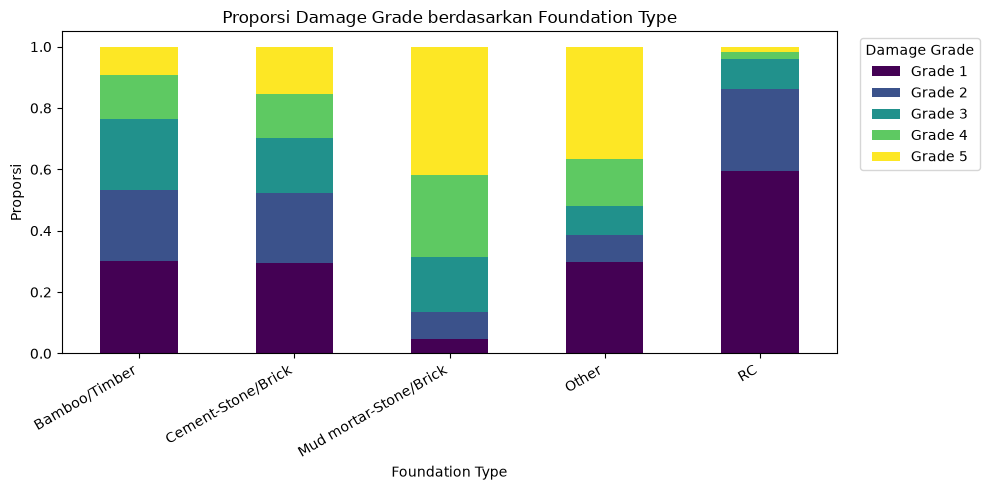

In [11]:
foundation_grade.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='viridis')
plt.title('Proporsi Damage Grade berdasarkan Foundation Type')
plt.xlabel('Foundation Type')
plt.ylabel('Proporsi')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Damage Grade', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_foundation_damage_grade.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Cardinality fitur kategorikal

Cardinality menunjukkan jumlah nilai unik. Informasi ini membantu menentukan fitur yang diperlakukan sebagai kategori.

In [12]:
categorical_columns = [
    'district_id', 'vdcmun_id', 'ward_id', 'land_surface_condition',
    'foundation_type', 'roof_type', 'ground_floor_type',
    'other_floor_type', 'position', 'plan_configuration',
    'superstructure',
]

cardinality = pd.DataFrame({
    'train_unique': train[categorical_columns].nunique(),
    'test_unique': test[categorical_columns].nunique(),
}).sort_values('train_unique', ascending=False)
cardinality

,train_unique,test_unique
ward_id,945,945
vdcmun_id,110,110
district_id,11,11
superstructure,11,11
plan_configuration,10,10
foundation_type,5,5
ground_floor_type,5,5
position,4,4
other_floor_type,4,4
roof_type,3,3


In [13]:
unseen_categories = {}
for column in categorical_columns:
    train_values = set(train[column].dropna().astype(str))
    test_values = set(test[column].dropna().astype(str))
    unseen_categories[column] = len(test_values - train_values)

pd.Series(unseen_categories, name='kategori_baru_di_test').to_frame()

,kategori_baru_di_test
district_id,0
vdcmun_id,0
ward_id,0
land_surface_condition,0
foundation_type,0
roof_type,0
ground_floor_type,0
other_floor_type,0
position,0
plan_configuration,0


Kategori yang hanya muncul pada test perlu ditangani saat preprocessing. Pipeline menggunakan mapping nilai tidak dikenal untuk LightGBM dan penanganan kategori dari CatBoost.

## 8. Fitur numerik menurut damage grade

In [14]:
numeric_by_grade = (
    train.groupby('damage_grade')[numeric_columns]
    .median()
    .round(2)
)
numeric_by_grade

,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq
damage_grade,,,,
Grade 1,2.0,7.0,400.0,14.0
Grade 2,2.0,12.0,380.0,15.0
Grade 3,2.0,16.0,364.0,16.0
Grade 4,2.0,20.0,350.0,16.0
Grade 5,2.0,20.0,342.0,16.0


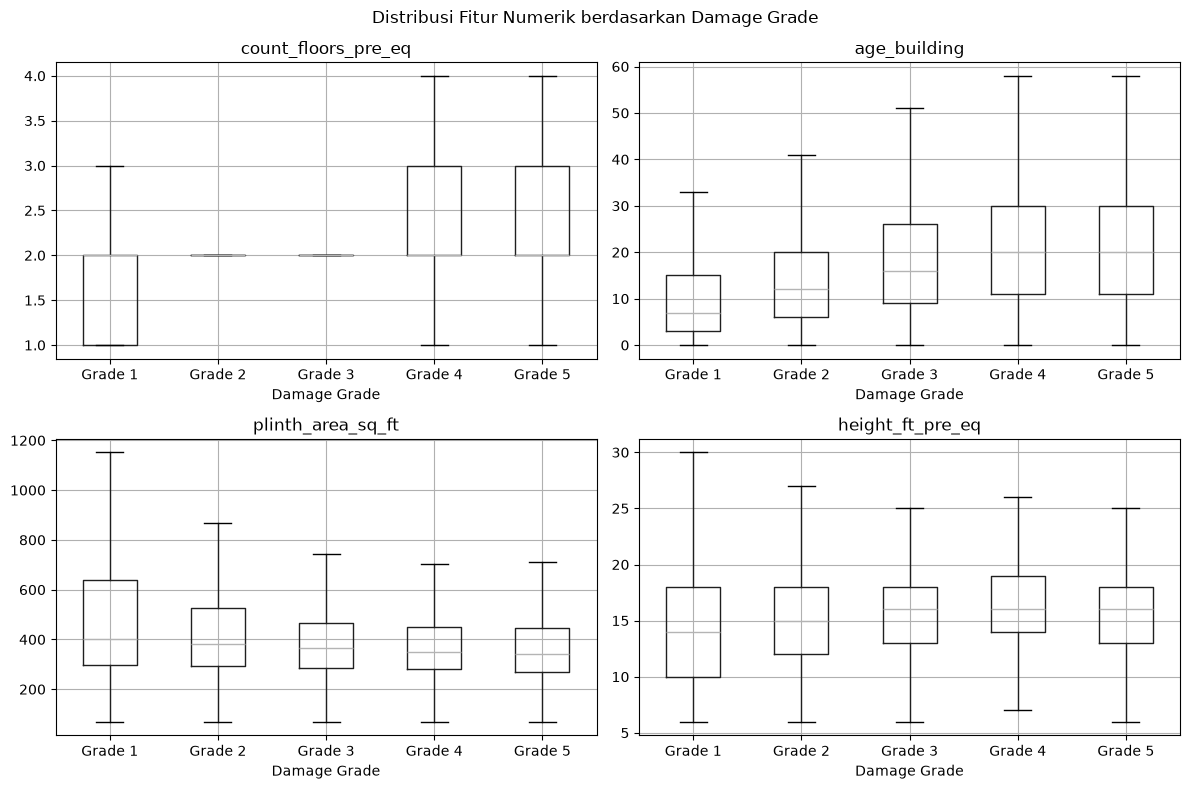

In [15]:
plot_data = train.sample(min(100000, len(train)), random_state=42).copy()
plot_data.loc[plot_data['age_building'] == 999, 'age_building'] = pd.NA

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, axis in zip(numeric_columns, axes.flatten()):
    plot_data.boxplot(
        column=column, by='damage_grade', ax=axis, showfliers=False
    )
    axis.set_title(column)
    axis.set_xlabel('Damage Grade')
plt.suptitle('Distribusi Fitur Numerik berdasarkan Damage Grade')
plt.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_numeric_features_by_grade.png', dpi=150, bbox_inches='tight')
plt.show()

Boxplot ditampilkan tanpa outlier agar perbedaan median dan rentang antar-grade lebih mudah dibaca. Outlier tetap dipertahankan pada data modeling.

## 9. Kelompok umur dan damage grade

In [16]:
age_for_group = train['age_building'].astype(float)
age_for_group = age_for_group.mask(age_for_group == 999)
age_group = pd.cut(
    age_for_group,
    bins=[-1, 10, 20, 40, 60, 100, float('inf')],
    labels=['0-10', '11-20', '21-40', '41-60', '61-100', '>100'],
)
age_grade = pd.crosstab(age_group, train['damage_grade'], normalize='index')
age_grade.round(3)

damage_grade,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
age_building,,,,,
0-10,0.206,0.163,0.173,0.181,0.277
11-20,0.082,0.111,0.186,0.242,0.378
21-40,0.036,0.080,0.178,0.283,0.423
41-60,0.020,0.065,0.175,0.314,0.426
61-100,0.016,0.058,0.185,0.338,0.404
>100,0.022,0.070,0.187,0.335,0.386


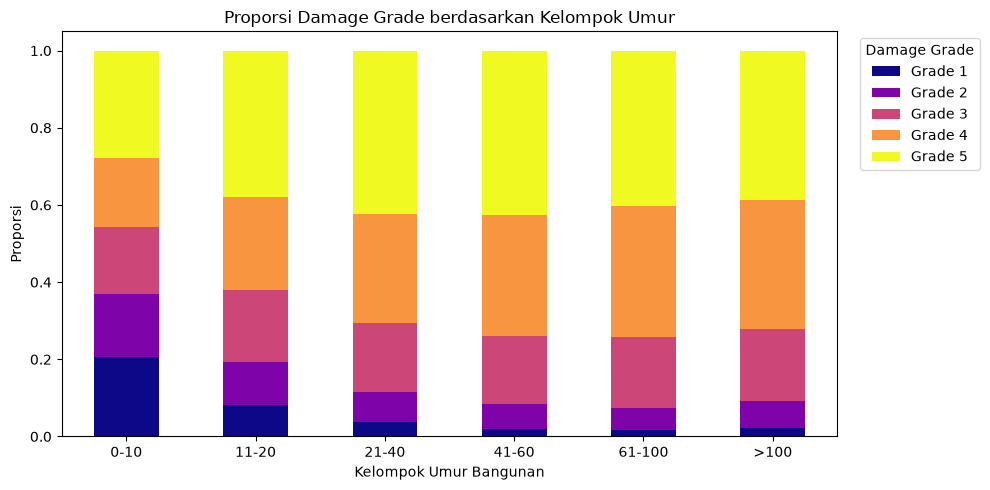

In [17]:
age_grade.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='plasma')
plt.title('Proporsi Damage Grade berdasarkan Kelompok Umur')
plt.xlabel('Kelompok Umur Bangunan')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Damage Grade', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_age_group_damage_grade.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Material bangunan dan target

In [18]:
material_count = train['superstructure'].value_counts()
material_count.to_frame('jumlah_bangunan')

,jumlah_bangunan
superstructure,
has_superstructure_mud_mortar_stone,415327
has_superstructure_cement_mortar_brick,33289
has_superstructure_timber,25407
has_superstructure_adobe_mud,22574
has_superstructure_rc_non_engineered,9051
has_superstructure_stone_flag,6994
has_superstructure_mud_mortar_brick,6746
has_superstructure_rc_engineered,5475
has_superstructure_cement_mortar_stone,4946


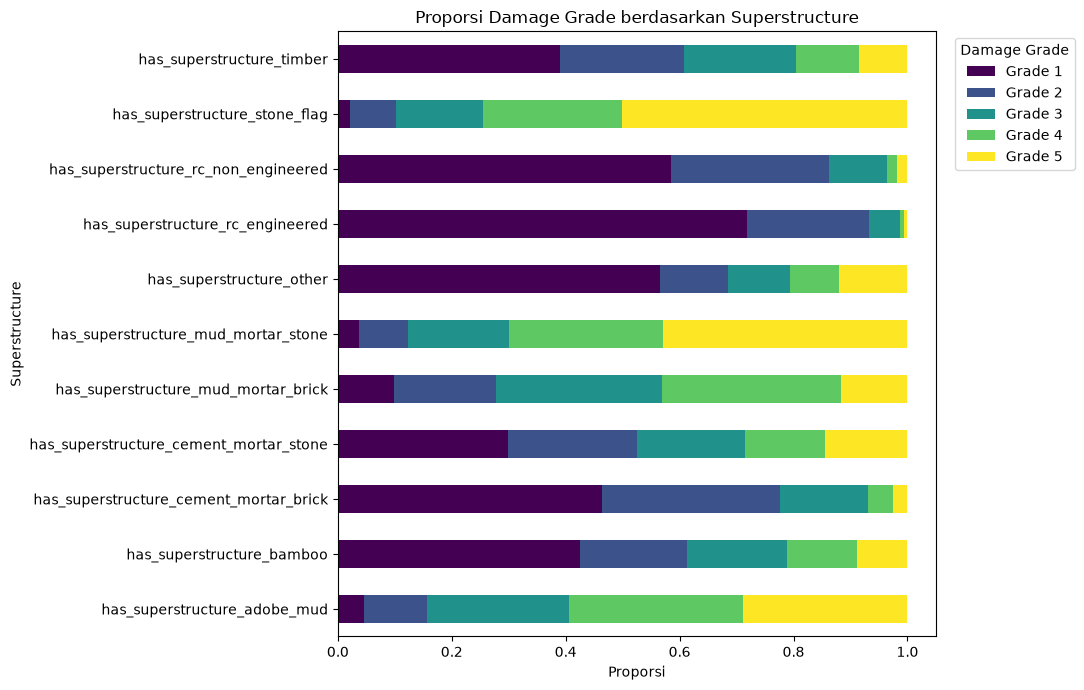

In [19]:
material_grade = pd.crosstab(
    train['superstructure'],
    train['damage_grade'],
    normalize='index',
)
material_grade.plot(
    kind='barh', stacked=True, figsize=(11, 7), colormap='viridis'
)
plt.title('Proporsi Damage Grade berdasarkan Superstructure')
plt.xlabel('Proporsi')
plt.ylabel('Superstructure')
plt.legend(title='Damage Grade', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_superstructure_damage_grade.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Ringkasan berdasarkan distrik

In [20]:
train_with_grade = train.assign(
    grade_number=train['damage_grade'].str.extract(r'(\d+)$')[0].astype(int)
)
district_summary = (
    train_with_grade.groupby('district_id')
    .agg(
        jumlah_bangunan=('building_id', 'count'),
        rata_rata_grade=('grade_number', 'mean'),
    )
    .sort_values('rata_rata_grade', ascending=False)
)
district_summary.round(3)

,jumlah_bangunan,rata_rata_grade
district_id,,
23,62165,4.680
29,8867,4.541
22,42465,4.310
28,53704,4.243
30,62461,3.892
36,54751,3.759
21,41095,3.553
24,68616,3.492
20,48133,2.876


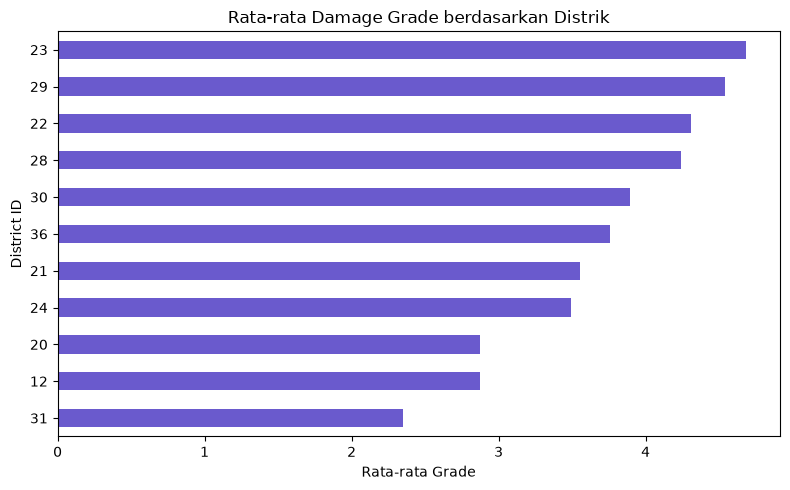

In [21]:
district_summary.sort_values('rata_rata_grade').plot.barh(
    y='rata_rata_grade', legend=False, figsize=(8, 5), color='slateblue'
)
plt.title('Rata-rata Damage Grade berdasarkan Distrik')
plt.xlabel('Rata-rata Grade')
plt.ylabel('District ID')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_district_average_grade.png', dpi=150, bbox_inches='tight')
plt.show()

District ID diperlakukan sebagai kategori pada model. Selisih rata-rata grade antar-distrik mendukung penggunaan fitur lokasi dan target encoding.

## 12. Perbandingan train dan test

In [22]:
train_numeric = train[numeric_columns].copy()
test_numeric = test[numeric_columns].copy()
train_numeric['age_building'] = train_numeric['age_building'].astype(float)
test_numeric['age_building'] = test_numeric['age_building'].astype(float)
train_numeric.loc[train_numeric['age_building'] == 999, 'age_building'] = float('nan')
test_numeric.loc[test_numeric['age_building'] == 999, 'age_building'] = float('nan')

train_test_numeric = pd.DataFrame({
    'train_mean': train_numeric.mean(),
    'test_mean': test_numeric.mean(),
    'train_median': train_numeric.median(),
    'test_median': test_numeric.median(),
}).round(2)
train_test_numeric

,train_mean,test_mean,train_median,test_median
count_floors_pre_eq,2.09,2.09,2.0,2.0
age_building,20.30,20.25,16.0,16.0
plinth_area_sq_ft,406.52,407.02,358.0,360.0
height_ft_pre_eq,16.05,16.05,16.0,16.0


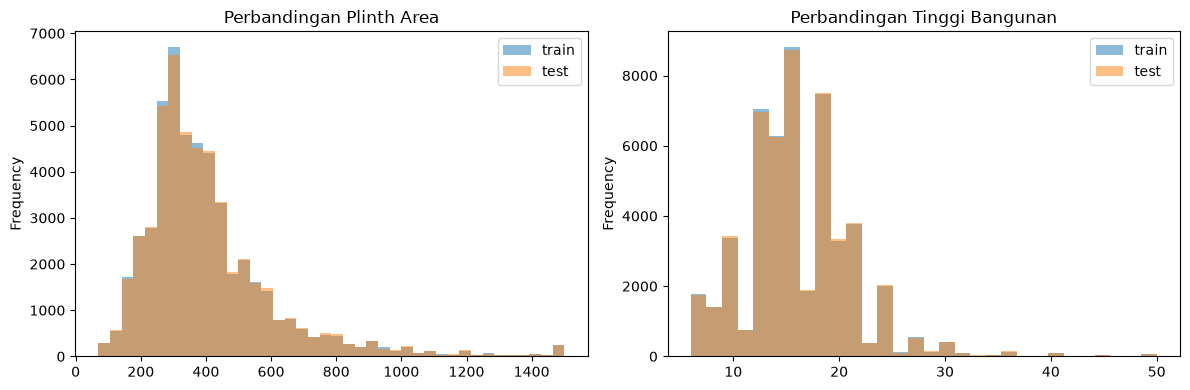

In [23]:
train_sample = train.sample(min(50000, len(train)), random_state=42)
test_sample = test.sample(min(50000, len(test)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_sample['plinth_area_sq_ft'].clip(upper=1500).plot(
    kind='hist', bins=40, alpha=0.5, label='train', ax=axes[0]
)
test_sample['plinth_area_sq_ft'].clip(upper=1500).plot(
    kind='hist', bins=40, alpha=0.5, label='test', ax=axes[0]
)
axes[0].set_title('Perbandingan Plinth Area')
axes[0].legend()

train_sample['height_ft_pre_eq'].clip(upper=50).plot(
    kind='hist', bins=30, alpha=0.5, label='train', ax=axes[1]
)
test_sample['height_ft_pre_eq'].clip(upper=50).plot(
    kind='hist', bins=30, alpha=0.5, label='test', ax=axes[1]
)
axes[1].set_title('Perbandingan Tinggi Bangunan')
axes[1].legend()
plt.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_train_test_numeric_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Korelasi fitur numerik

In [24]:
correlation_data = train_with_grade[numeric_columns + ['grade_number']].copy()
correlation_data['age_building'] = correlation_data['age_building'].astype(float)
correlation_data.loc[
    correlation_data['age_building'] == 999, 'age_building'
] = float('nan')
correlation = correlation_data.corr()
correlation.round(3)

,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,grade_number
count_floors_pre_eq,1.000,0.168,0.102,0.712,0.190
age_building,0.168,1.000,-0.051,0.106,0.214
plinth_area_sq_ft,0.102,-0.051,1.000,0.203,-0.168
height_ft_pre_eq,0.712,0.106,0.203,1.000,0.056
grade_number,0.190,0.214,-0.168,0.056,1.000


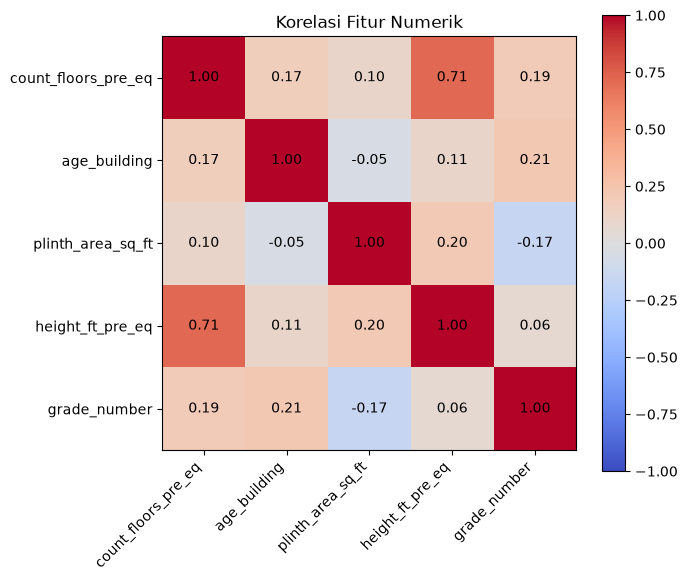

In [25]:
fig, axis = plt.subplots(figsize=(7, 6))
image = axis.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
axis.set_yticks(range(len(correlation.index)), correlation.index)
for row in range(len(correlation.index)):
    for column in range(len(correlation.columns)):
        axis.text(column, row, f'{correlation.iloc[row, column]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=axis)
axis.set_title('Korelasi Fitur Numerik')
plt.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_numeric_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Kesimpulan EDA

- Target terdiri dari lima kelas dan distribusinya tidak seimbang.
- Nilai umur 999 perlu dipisahkan dari umur bangunan yang sebenarnya.
- Foundation, superstructure, umur, dan lokasi menunjukkan distribusi grade yang berbeda.
- ID wilayah digunakan sebagai kategori. Building ID lengkap tidak digunakan karena unik untuk setiap baris.
- Perbandingan train dan test digunakan untuk memeriksa perbedaan distribusi sebelum training.